In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [6]:
df=pd.read_excel("Project_38_Market_Basket_Dataset.xlsx",sheet_name="Transactions")
print(df.shape)
print(df.head())

(16097, 3)
   BasketID    Item  Quantity
0         1    Milk         1
1         1    Eggs         2
2         1  Cheese         3
3         2  Cheese         1
4         3   Bread         3


In [10]:
print(len(df))
print(df["BasketID"].nunique())
print(df["Item"].nunique())

16097
5000
12


In [15]:
print(df.isnull().sum())
(sorted(df["Item"].unique()))


BasketID    0
Item        0
Quantity    0
dtype: int64


['Bread',
 'Butter',
 'Cheese',
 'Chips',
 'Coffee',
 'Eggs',
 'Milk',
 'Pasta',
 'Pasta Sauce',
 'Soda',
 'Sugar',
 'Tea']

In [19]:
basket_present=pd.crosstab(
    df["BasketID"],
        df["Item"]
)
basket_present.shape
basket_present.head(20)

Item,Bread,Butter,Cheese,Chips,Coffee,Eggs,Milk,Pasta,Pasta Sauce,Soda,Sugar,Tea
BasketID,,,,,,,,,,,,
1,0,0,1,0,0,1,1,0,0,0,0,0
2,0,0,1,0,0,0,0,0,0,0,0,0
3,1,1,0,1,0,1,0,0,0,1,0,0
4,0,0,0,1,0,1,0,0,0,1,0,0
5,1,0,1,0,1,0,1,0,0,1,0,0
6,0,0,0,0,0,1,0,1,1,0,0,0
7,1,0,1,0,0,1,0,0,0,1,0,0
8,1,0,1,0,0,0,0,1,1,0,1,1
9,1,0,1,0,1,0,0,0,0,0,0,0


In [18]:
basket_count=(basket_present > 0).astype(int)
basket_count.head()

Item,Bread,Butter,Cheese,Chips,Coffee,Eggs,Milk,Pasta,Pasta Sauce,Soda,Sugar,Tea
BasketID,,,,,,,,,,,,
1,0,0,1,0,0,1,1,0,0,0,0,0
2,0,0,1,0,0,0,0,0,0,0,0,0
3,1,1,0,1,0,1,0,0,0,1,0,0
4,0,0,0,1,0,1,0,0,0,1,0,0
5,1,0,1,0,1,0,1,0,0,1,0,0


In [27]:
print(basket_count.shape[0])
print(basket_count.shape[1])
print(np.unique(basket_count.values))



5000
12
[0 1]


In [30]:
item_in_all_basket=basket_count.mean()
item_in_all_basket

Item
Bread          0.4496
Butter         0.3460
Cheese         0.2258
Chips          0.2432
Coffee         0.1984
Eggs           0.2852
Milk           0.3274
Pasta          0.1974
Pasta Sauce    0.2814
Soda           0.2432
Sugar          0.2312
Tea            0.1906
dtype: float64

In [31]:
item_percent=item_in_all_basket * 100
item_percent.round(2)

Item
Bread          44.96
Butter         34.60
Cheese         22.58
Chips          24.32
Coffee         19.84
Eggs           28.52
Milk           32.74
Pasta          19.74
Pasta Sauce    28.14
Soda           24.32
Sugar          23.12
Tea            19.06
dtype: float64

In [32]:
item_percent.sort_values(ascending=False).round(2)

Item
Bread          44.96
Butter         34.60
Milk           32.74
Eggs           28.52
Pasta Sauce    28.14
Chips          24.32
Soda           24.32
Sugar          23.12
Cheese         22.58
Coffee         19.84
Pasta          19.74
Tea            19.06
dtype: float64

In [35]:
basket_table=pd.crosstab(
    df["BasketID"],
        df["Item"]
)
basket_present.shape
basket_present.head()

Item,Bread,Butter,Cheese,Chips,Coffee,Eggs,Milk,Pasta,Pasta Sauce,Soda,Sugar,Tea
BasketID,,,,,,,,,,,,
1,0,0,1,0,0,1,1,0,0,0,0,0
2,0,0,1,0,0,0,0,0,0,0,0,0
3,1,1,0,1,0,1,0,0,0,1,0,0
4,0,0,0,1,0,1,0,0,0,1,0,0
5,1,0,1,0,1,0,1,0,0,1,0,0


In [36]:
X = basket_table.to_numpy()

pair_counts = X.T @ X

display(pd.DataFrame(
    pair_counts,
    index=basket_table.columns,
    columns=basket_table.columns
))

Item,Bread,Butter,Cheese,Chips,Coffee,Eggs,Milk,Pasta,Pasta Sauce,Soda,Sugar,Tea
Item,,,,,,,,,,,,
Bread,2248,1096,498,528,447,631,720,467,657,554,528,432
Butter,1096,1730,395,412,337,483,543,348,473,421,377,319
Cheese,498,395,1129,258,230,313,355,199,273,268,259,188
Chips,528,412,258,1216,229,318,384,218,328,571,291,237
Coffee,447,337,230,229,992,289,588,208,305,273,171,46
Eggs,631,483,313,318,289,1426,447,279,396,343,299,274
Milk,720,543,355,384,588,447,1637,347,473,391,361,266
Pasta,467,348,199,218,208,279,347,987,757,219,196,168
Pasta Sauce,657,473,273,328,305,396,473,757,1407,326,299,244


In [37]:
items_count=X.sum(axis=0)
items_count

array([2248, 1730, 1129, 1216,  992, 1426, 1637,  987, 1407, 1216, 1156,
        953])

In [41]:
supports = items_count / len(basket_table)
supports

array([0.4496, 0.346 , 0.2258, 0.2432, 0.1984, 0.2852, 0.3274, 0.1974,
       0.2814, 0.2432, 0.2312, 0.1906])

In [42]:
item_counts = X.sum(axis=0)
supports = item_counts / len(basket_table)

rules = []

items = list(basket_table.columns)

for i in range(len(items)):
    for j in range(len(items)):
        if i != j:
            count = pair_counts[i, j]

            support = count / len(basket_table)
            confidence = count / item_counts[i]
            lift = confidence / supports[j]

            if support >= 0.05:
                rules.append([
                    items[i], items[j],
                    support, confidence, lift
                ])

rules_df = pd.DataFrame(
    rules,
    columns=["Item A", "Item B", "Support", "Confidence", "Lift"] # support=two items combined present ,; # confidence=item A bought people also bought item B ,; # lift=2 items association strength 
)

rules_df = rules_df.sort_values("Lift", ascending=False)

display(rules_df.head(10).round(3))

,Item A,Item B,Support,Confidence,Lift
78,Pasta Sauce,Pasta,0.151,0.538,2.726
70,Pasta,Pasta Sauce,0.151,0.767,2.726
98,Sugar,Tea,0.106,0.458,2.401
103,Tea,Sugar,0.106,0.555,2.401
36,Chips,Soda,0.114,0.470,1.931
84,Soda,Chips,0.114,0.470,1.931
59,Milk,Coffee,0.118,0.359,1.810
41,Coffee,Milk,0.118,0.593,1.810
11,Butter,Bread,0.219,0.634,1.409
0,Bread,Butter,0.219,0.488,1.409


In [43]:
item_percent.sort_values(ascending=False).round(2)

Item
Bread          44.96
Butter         34.60
Milk           32.74
Eggs           28.52
Pasta Sauce    28.14
Chips          24.32
Soda           24.32
Sugar          23.12
Cheese         22.58
Coffee         19.84
Pasta          19.74
Tea            19.06
dtype: float64

In [44]:
display(rules_df.head(10).round(3))

,Item A,Item B,Support,Confidence,Lift
78,Pasta Sauce,Pasta,0.151,0.538,2.726
70,Pasta,Pasta Sauce,0.151,0.767,2.726
98,Sugar,Tea,0.106,0.458,2.401
103,Tea,Sugar,0.106,0.555,2.401
36,Chips,Soda,0.114,0.470,1.931
84,Soda,Chips,0.114,0.470,1.931
59,Milk,Coffee,0.118,0.359,1.810
41,Coffee,Milk,0.118,0.593,1.810
11,Butter,Bread,0.219,0.634,1.409
0,Bread,Butter,0.219,0.488,1.409


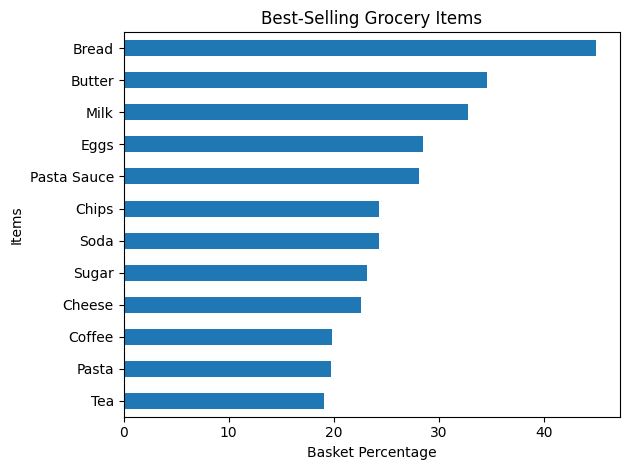

In [45]:
item_percent.sort_values().plot(kind="barh")

plt.title("Best-Selling Grocery Items")
plt.xlabel("Basket Percentage")
plt.ylabel("Items")
plt.tight_layout()
plt.savefig("chart.png")
plt.show()

In [46]:
rules_df.to_csv("association_rules.csv", index=False)
basket_table.to_csv("basket_table.csv")

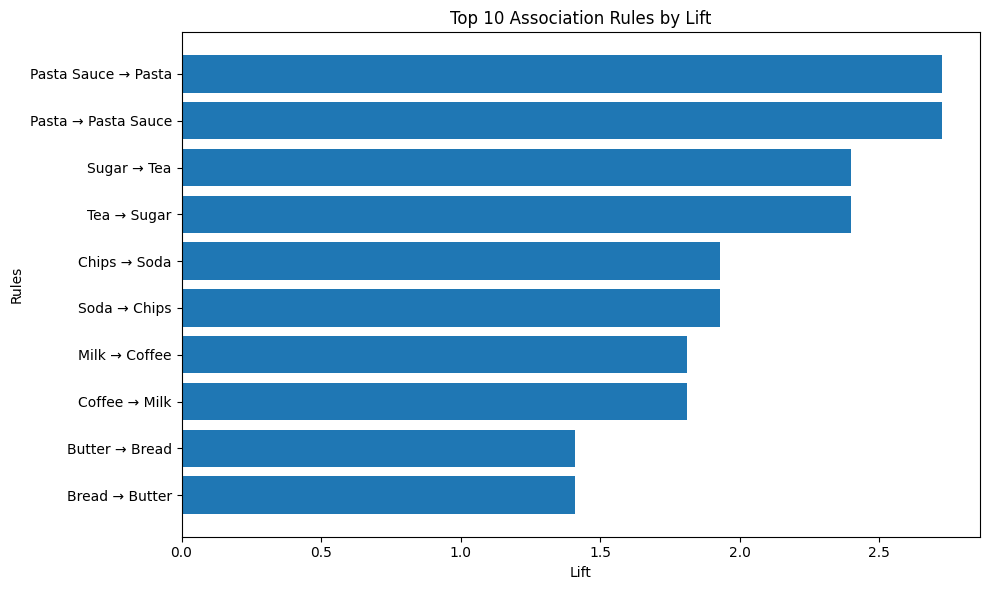

In [47]:
top10 = rules_df.sort_values("Lift", ascending=False).head(10)

plt.figure(figsize=(10, 6))
plt.barh(
    top10["Item A"] + " → " + top10["Item B"],
    top10["Lift"]
)

plt.title("Top 10 Association Rules by Lift")
plt.xlabel("Lift")
plt.ylabel("Rules")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("top10_lift_chart.png", dpi=120)
plt.show()